# 평가 심화 실습: 입력 파일에서 두 줄씩 골라 회귀와 비용 보기

**이 노트북에서 할 일**

1. 08절이 쓴 입력 파일을 읽고, 요청 식별자의 질문 번호로 두 줄을 고릅니다.
2. 고른 두 줄의 판정 요청 글을 평가 모델에 하나씩 보내 07절 검사를 겁니다.
3. 응답의 사용량으로 06절처럼 요청마다 예상 비용을 셉니다.
4. 고른 질문 번호만 바꿔 한 번 더 실행하고 두 실행을 견줍니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
평가 모델 `gpt-5.4-mini`에 보내는 요청은 네 번이고 임베딩 요청은 없습니다.
실행 1과 실행 2가 두 번씩 보냅니다.
예상 비용은 미화 0.01달러 아래이고 실제 청구 금액과는 다를 수 있습니다.
일괄 처리로 제출하지 않고 파일에 적힌 요청을 하나씩 보냅니다.

읽는 파일은 08절이 쓴 입력 파일 `runs/batch-eval-input.jsonl` 하나입니다.
이 파일은 읽기만 하고 다시 쓰지 않습니다. 새로 쓰는 파일도 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 1분 안에 끝났습니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~08절에서 쓴 이름과 문법만 씁니다.

실습 폴더 `labs/part4/ch15-evaluation-advanced`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 runs batch-eval-input.jsonl 여섯 줄 읽기만에서 파란 상자 lines_for 08절 요청 식별자로 두 줄 고르기를 지나 보라 상자 gpt-5.4-mini 줄마다 판정 한 번으로 가고, 거기서 화살표 둘이 나와 왼쪽은 파란 상자 scores_for로 점수 07절 check_by_case를 지나 노란 상자 깨진 사례와 통과 여부로, 오른쪽은 파란 상자 print_costs 안의 06절 estimate_cost를 지나 노란 상자 요청마다 예상 비용으로 이어지는 그림](attachment:09-1-입력-파일에서-검사와-비용까지.png)

위에서 아래로 읽습니다. 초록 입력 파일에서 파란 상자가 두 줄을 고르고, 보라 평가 모델이 줄마다 한 번씩 판정합니다.
보라 상자에서 화살표 둘이 나옵니다. 왼쪽은 07절 검사로, 오른쪽은 06절 예상 비용으로 가고 둘 다 실행됩니다.
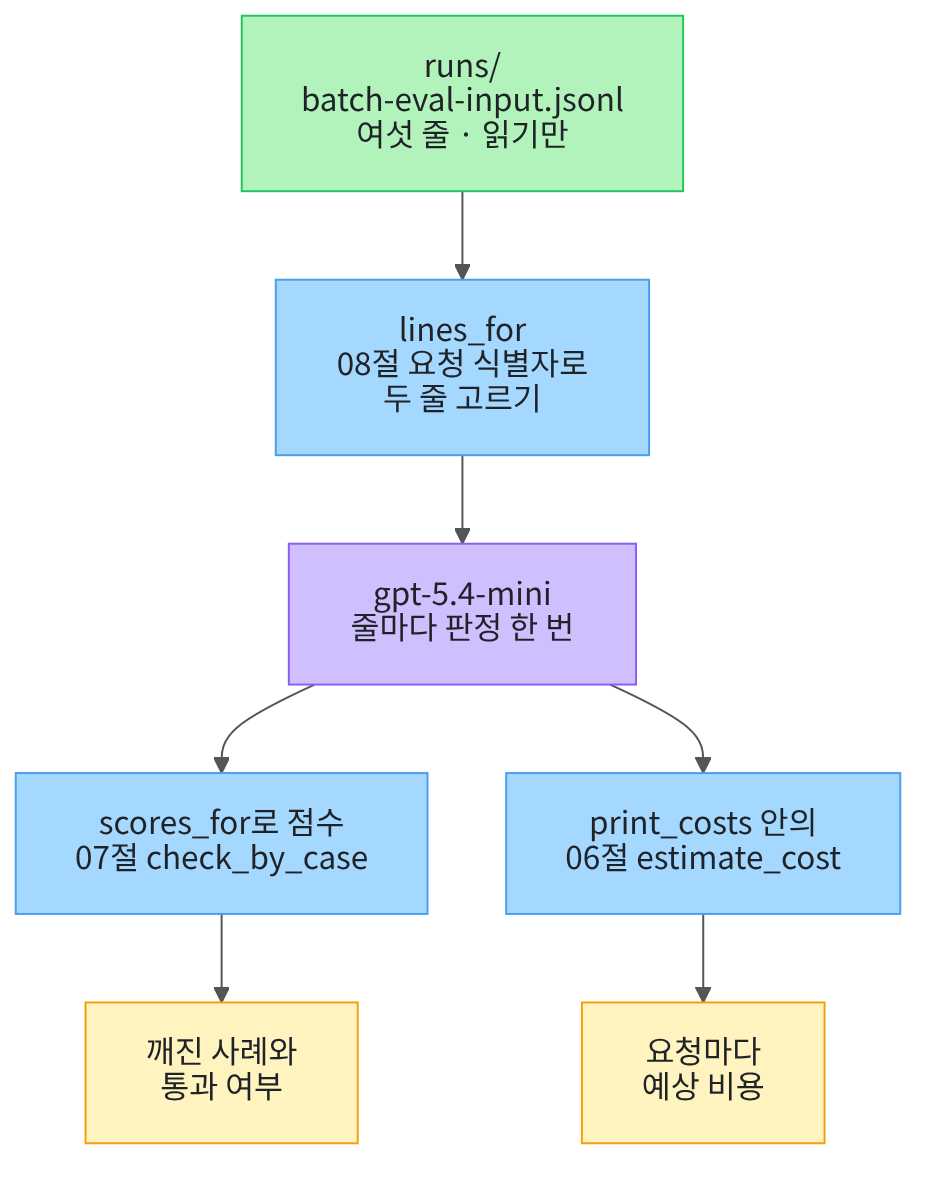

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01~08절에서 쓴 이름과 문법만 쓰고 따로 내는 과제는 없습니다.
첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 불러오고 앞에서 배운 함수 다섯을 도구 파일에서 가져옵니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 07절 `broken_cases()`·`check_by_case()`와 08절 `read_jsonl()`·`ids_not_in()`을 가져옵니다.
Ch 6 06절 `estimate_cost()`도 가져옵니다.

In [2]:
# 파일 읽기·폴더 확인에 쓸 이름과 모델을 준비하는 이름을 불러옵니다
import json
import os

from langchain.chat_models import init_chat_model

# Ch 6 06절 함수 하나와 Ch 15 07·08절 함수 넷을 도구 파일에서 가져옵니다
from rag_tools import broken_cases, check_by_case, estimate_cost, ids_not_in, read_jsonl

print("불러온 이름:", "json", "os", "init_chat_model")

불러온 이름: json os init_chat_model


**결과 읽기** — 출력 줄 `불러온 이름: json os init_chat_model`로 이름 세 개를 불러왔습니다.
도구 파일에서 가져온 함수 다섯은 출력하지 않습니다.

07절 함수 둘과 08절 함수 둘은 그 절 본문 그대로 도구 파일에 옮겼고, 인자도 그때와 같습니다.
함수 `check_by_case()`가 안에서 부르는 07절 `check_by_average()`도 함께 옮겼습니다.
함수 `estimate_cost()`는 06절이 옮긴 Ch 6 06절 함수 그대로입니다.

## 2. 키와 모델 준비

이 절도 02~07절과 같은 평가 모델 `gpt-5.4-mini`를 부릅니다.
모델을 만드는 설정 값도 07절과 같습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 판정 점수가 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 입력 파일 읽기

이 실습의 상황은 이렇습니다.
08절은 판정 요청 여섯 개를 입력 파일에 담았고 제출은 하지 않았습니다.
여섯 줄을 한꺼번에 맡기기 전에 두 줄만 골라 하나씩 보내 봅니다.
파일에 든 판정 요청 글이 판정되는지와 요청 한 번의 비용을 먼저 보려는 것입니다.

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01~08절과 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch15-evaluation-advanced/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 08절이 쓴 입력 파일을 08절 함수 `read_jsonl()`로 읽습니다.
파일은 내려받은 실습 자료에 들어 있습니다.
08절 노트북을 다시 실행해도 같은 내용으로 다시 써집니다.
이 절은 파일을 읽기만 하고 다시 쓰지 않습니다.

In [6]:
# 08절이 쓴 입력 파일을 읽어 줄 수와 요청 식별자를 봅니다(읽기만 하고 다시 쓰지 않습니다)
batch_path = root_path + "/labs/part4/ch15-evaluation-advanced/runs/batch-eval-input.jsonl"
batch_lines = read_jsonl(batch_path)
request_ids = []
for line in batch_lines:
    request_ids.append(line["custom_id"])
print("읽은 줄 수:", len(batch_lines))
print("요청 식별자:", request_ids)

읽은 줄 수: 6
요청 식별자: ['old-Q002', 'old-Q006', 'old-Q090', 'new-Q002', 'new-Q006', 'new-Q090']


**결과 읽기** — 출력 줄 `읽은 줄 수: 6`으로 입력 파일의 요청은 여섯 줄입니다.
출력 줄 `요청 식별자:` 뒤 목록이 08절이 붙인 이름이고, `old-Q002`부터 `new-Q090`까지입니다.
판 표시 `old`는 이전 판, `new`는 이후 판이고 줄표 뒤가 질문 번호입니다.

다음 셀은 요청 주소와 본문 설정을 2절에서 만든 모델과 견줍니다.
본문 설정이 같아야 파일의 요청 글을 이 모델로 보내도 같은 설정의 요청이 됩니다.

In [7]:
# 여섯 줄의 요청 주소와 본문 설정을 2절에서 만든 모델과 견줍니다(요청 없음)
first_body = batch_lines[0]["body"]
print("첫 줄 요청 주소:", batch_lines[0]["url"])
print("첫 줄 본문 설정:", first_body["model"], first_body["temperature"], first_body["reasoning_effort"])
print("모델 객체:", model.model_name, model.temperature)
same_count = 0
for line in batch_lines:
    if line["body"]["model"] == model.model_name and line["body"]["temperature"] == model.temperature:
        same_count = same_count + 1
print("모델 이름과 temperature가 같은 줄 수:", same_count)

첫 줄 요청 주소: /v1/chat/completions
첫 줄 본문 설정: gpt-5.4-mini 0 none
모델 객체: gpt-5.4-mini 0.0
모델 이름과 temperature가 같은 줄 수: 6


**결과 읽기** — 출력 줄 `첫 줄 요청 주소: /v1/chat/completions`는 08절이 정한 요청 주소입니다.
출력 줄 `첫 줄 본문 설정: gpt-5.4-mini 0 none`과 `모델 객체: gpt-5.4-mini 0.0`을 견줍니다.
출력 줄 `모델 이름과 temperature가 같은 줄 수: 6`으로 여섯 줄 모두 같았습니다.

본문의 `0`과 모델 객체의 `0.0`은 적는 모양만 다르고 같은 값으로 셉니다.
추론 설정 `none`은 2절 모델 셀에서 `reasoning_effort="none"`으로 준 값과 같습니다.
08절에서 본 것처럼 이 과정의 LangChain 판은 이 설정의 요청을 같은 주소로 보냅니다.

## 4. 요금표와 줄 고르기

다음 셀은 06절 요금표를 같은 키 이름과 값으로 다시 적습니다.
요청 한 번의 예상 비용을 셀 때 씁니다.

In [8]:
# 06절 요금표(100만 토큰당 달러)를 같은 키 이름과 값으로 다시 적고 확인한 날짜도 적습니다
pricing_date = "2026-09-17"
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
print("요금 확인 날짜:", pricing_date)
print("mini 요금:", mini_prices)

요금 확인 날짜: 2026-09-17
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-17`은 Ch 6 06절에서 요금을 확인한 날입니다.
출력 줄 `mini 요금:` 뒤 딕셔너리가 100만 토큰당 달러입니다.

코드에 적은 `4.50`은 출력에서 `4.5`로 보입니다.
다음 셀은 입력 파일에서 질문 번호가 같은 줄만 고르는 함수입니다.
08절에서 요청 식별자를 `split("-")`로 나눠 판 표시와 질문 번호를 읽은 방법을 씁니다.

In [9]:
# 입력 파일의 줄 가운데 요청 식별자의 질문 번호가 같은 줄만 파일 차례대로 고릅니다
def lines_for(lines, qid):
    chosen_lines = []
    for line in lines:
        parts = line["custom_id"].split("-")
        if parts[1] == qid:
            chosen_lines.append(line)
    return chosen_lines

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `lines_for`는 요청 식별자를 줄표로 나눠 둘째 값이 질문 번호와 같은 줄만 모읍니다.
고른 줄은 파일 차례대로 목록에 들어가므로 이전 판 줄이 먼저 옵니다.

다음 셀은 실행 1에서 보낼 줄을 미리 골라 봅니다. 요청은 보내지 않습니다.

In [10]:
# 실행 1에서 보낼 질문 번호 Q090의 줄을 미리 고르고 요청 식별자와 요청 글 글자 수를 봅니다(요청 없음)
preview_lines = lines_for(batch_lines, "Q090")
print("고른 줄 수:", len(preview_lines))
print("요청 식별자 | 요청 글 글자 수")
for line in preview_lines:
    content = line["body"]["messages"][0]["content"]
    print(line["custom_id"], "|", len(content))

고른 줄 수: 2
요청 식별자 | 요청 글 글자 수
old-Q090 | 5093
new-Q090 | 5117


**결과 읽기** — 출력 줄 `고른 줄 수: 2`로 질문 번호 Q090의 줄은 두 줄입니다.
라벨 줄 `요청 식별자 | 요청 글 글자 수` 아래 `old-Q090 | 5093`과 `new-Q090 | 5117`이 보입니다.
두 글자 수는 07·08절 출력의 Q090 글자 수와 같습니다.

사례 하나에 이전 판과 이후 판이 한 줄씩 있습니다.
그래서 두 줄을 보내면 07절처럼 두 판을 짝지어 볼 수 있습니다.

## 5. 기록 장치와 조립

다음 셀은 고른 줄을 평가 모델에 보내는 함수입니다.
줄마다 본문 메시지의 내용이 판정 요청 글입니다.
06절처럼 응답 객체를 통째로 모아 두면 점수와 사용량을 함께 꺼낼 수 있습니다.

In [11]:
# 고른 줄마다 본문 메시지의 판정 요청 글을 평가 모델에 보내고 응답 객체를 요청 식별자별로 모읍니다(줄 하나에 모델 요청 1번)
def send_lines(judge_model, chosen_lines):
    replies = {}
    for line in chosen_lines:
        prompt_text = line["body"]["messages"][0]["content"]
        replies[line["custom_id"]] = judge_model.invoke(prompt_text)
    return replies

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `send_lines`는 줄마다 `invoke()`를 한 번씩 불러 응답 객체를 요청 식별자별로 모읍니다.
고른 줄이 두 줄이면 모델 요청이 두 번 나갑니다.
파일에 적힌 설정 칸은 보내지 않고, 같은 설정으로 만든 모델 객체가 요청을 보냅니다.

다음 셀은 응답 객체에서 한 판의 점수만 모으는 함수입니다.

In [12]:
# 응답 객체 가운데 판 표시가 같은 것만 골라 JSON 글을 읽고 점수를 질문 번호별로 모읍니다
def scores_for(replies, version_tag):
    scores = {}
    for custom_id in replies:
        parts = custom_id.split("-")
        if parts[0] == version_tag:
            verdict = json.loads(replies[custom_id].text)
            scores[parts[1]] = verdict["score"]
    return scores

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `scores_for`는 요청 식별자의 판 표시가 같은 응답만 골라 JSON 글을 읽습니다.
점수는 질문 번호를 키로 모으므로 07절 점수 딕셔너리와 모양이 같습니다.
그래서 07절 함수에 그대로 넣을 수 있습니다.

다음 셀은 앞 절 기능을 한 흐름으로 잇는 조립 함수입니다.
08절 줄 고르기, 파일 속 판정 요청 글 보내기, 07절 검사를 차례로 합니다.

In [13]:
# 08절 줄 고르기 → 판정 요청 → 07절 짝지어 보는 검사를 한 흐름으로 잇습니다(고른 줄 하나에 모델 요청 1번)
def check_question(judge_model, lines, qid):
    # 08절: 요청 식별자의 질문 번호로 두 줄을 고릅니다
    chosen_lines = lines_for(lines, qid)
    # 02절 판정 요청 글(파일 본문에 든 글)을 줄마다 보냅니다
    replies = send_lines(judge_model, chosen_lines)
    old_scores = scores_for(replies, "old")
    new_scores = scores_for(replies, "new")
    result = {"응답": replies, "이전 판": old_scores, "이후 판": new_scores}
    # 07절: 깨진 사례와 짝지어 보는 검사
    result["깨진 사례"] = broken_cases(old_scores, new_scores)
    result["통과"] = check_by_case(old_scores, new_scores)
    return result

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `check_question`은 질문 번호 하나를 받아 두 줄을 보내고 두 판 점수를 모읍니다.
07절 `broken_cases()`로 깨진 사례를 찾고, `check_by_case()`로 짝지어 본 검사 결과를 냅니다.
결과는 응답·두 판 점수·깨진 사례·통과를 담은 딕셔너리 하나입니다.

다음 셀은 응답 객체의 사용량으로 예상 비용을 세어 출력하는 함수입니다.
06절처럼 요청마다 `estimate_cost()`를 한 번씩 부릅니다.

In [14]:
# 응답 객체마다 사용량과 요금표로 06절처럼 예상 비용을 세어 한 줄씩 출력하고 합도 출력합니다(요청 없음)
def print_costs(replies, prices):
    total_cost = 0
    print("요청 식별자 | 입력 토큰 수 | 캐시 입력 토큰 수 | 출력 토큰 수 | 예상 비용(달러)")
    for custom_id in replies:
        usage = replies[custom_id].usage_metadata
        cost = estimate_cost(usage, prices["ordinary_input"], prices["cached_input"], prices["output"])
        total_cost = total_cost + cost
        print(custom_id, "|", usage["input_tokens"], "|", usage["input_token_details"]["cache_read"], "|", usage["output_tokens"], "|", round(cost, 8))
    print("예상 비용 합(달러):", round(total_cost, 8))

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_costs`는 응답마다 입력·캐시 입력·출력 토큰 수와 예상 비용을 한 줄씩 출력합니다.
마지막 줄에는 출력한 요청들의 예상 비용 합을 적습니다.
입력 가운데 캐시 입력은 싼 요금으로, 나머지는 일반 입력 요금으로 셉니다.

이것으로 부품과 기록 장치를 모두 만들었습니다.
실행 1·2가 고를 두 사례 Q090·Q002는 흐름을 보여 주려고 07절 결과를 보고 정한 예입니다.

## 6. 실행 1 · 질문 번호 Q090

실행 1은 질문 번호 Q090의 두 줄을 보냅니다.
실행 전에 예상해 봅니다.
07절에서 이 사례는 이전 판 0, 이후 판 1이었습니다.
같은 판정이 나오면 깨진 사례가 없고 짝지어 본 검사를 통과할 것입니다.
이 셀에서 모델 요청이 두 번 나갑니다.

In [15]:
# 실행 1은 질문 번호 Q090의 두 줄을 파일에서 골라 하나씩 보냅니다(모델 요청 2번)
chosen_qid = "Q090"
run1 = check_question(model, batch_lines, chosen_qid)
run1_ids = list(run1["응답"].keys())
print("고른 질문 번호:", chosen_qid)
print("보낸 요청 식별자:", run1_ids)

고른 질문 번호: Q090
보낸 요청 식별자: ['old-Q090', 'new-Q090']


**결과 읽기** — 출력 줄 `고른 질문 번호: Q090`과 `보낸 요청 식별자: ['old-Q090', 'new-Q090']`로 두 줄을 보냈습니다.
응답 객체는 결과 딕셔너리의 칸 `응답`에 요청 식별자별로 들어 있습니다.

다음 셀은 두 판 점수와 07절 검사 결과를 봅니다.

In [16]:
# 실행 1의 두 판 점수와 07절 검사 결과를 봅니다(요청 없음)
print("이전 판 점수:", run1["이전 판"])
print("이후 판 점수:", run1["이후 판"])
print("깨진 사례(1 → 0):", run1["깨진 사례"])
print("짝지어 본 검사 통과:", run1["통과"])

이전 판 점수: {'Q090': 0}
이후 판 점수: {'Q090': 1}
깨진 사례(1 → 0): []
짝지어 본 검사 통과: True


**결과 읽기** — 출력 줄 `이전 판 점수:`와 `이후 판 점수:` 뒤가 질문 번호별 점수입니다.
출력 줄 `깨진 사례(1 → 0):`와 `짝지어 본 검사 통과:` 뒤가 07절 검사 결과입니다.

이번 실행에서 사례 Q090은 이전 판 0, 이후 판 1이었습니다.
깨진 사례는 없었고 짝지어 본 검사는 True, 곧 통과였습니다.
예상과 같았고, 새 커널로 두 번 실행했을 때 두 번 모두 같았습니다.
판정은 모델이 쓴 글이라 여러분 실행에서는 다를 수 있습니다.

다음 셀은 두 응답의 사용량으로 요청마다 예상 비용을 셉니다.

In [17]:
# 실행 1에서 받은 두 응답의 사용량으로 요청마다 예상 비용을 셉니다(요청 없음)
print("실행 1의 응답 수:", len(run1["응답"]))
print_costs(run1["응답"], mini_prices)

실행 1의 응답 수: 2
요청 식별자 | 입력 토큰 수 | 캐시 입력 토큰 수 | 출력 토큰 수 | 예상 비용(달러)
old-Q090 | 3248 | 2816 | 48 | 0.0007512
new-Q090 | 3266 | 2816 | 61 | 0.0008232
예상 비용 합(달러): 0.0015744


**결과 읽기** — 출력 줄 `실행 1의 응답 수: 2`로 두 응답을 셉니다.
라벨 줄 `요청 식별자 | 입력 토큰 수 | 캐시 입력 토큰 수 | 출력 토큰 수 | 예상 비용(달러)` 아래 두 줄이 두 요청입니다.
줄 `old-Q090 | 3248`과 `new-Q090 | 3266`처럼 요청 글이 긴 이후 판의 입력 토큰이 조금 많습니다.

이번 실행에서 캐시 입력 토큰 수는 두 줄 모두 2816이었고, 출력 토큰 수는 48과 61이었습니다.
예상 비용은 0.0007512달러와 0.0008232달러였고 합은 0.0015744달러였습니다.
새 커널로 두 번 실행했을 때 입력 토큰 수는 같았고, 출력 토큰 수와 예상 비용은 달랐습니다.
캐시 입력 토큰 수는 여러분 실행에서 0일 수 있고, 그러면 같은 요금표로도 예상 비용이 커집니다.

## 7. 실행 2 · 질문 번호 Q002

실행 2는 고른 질문 번호만 Q002로 바꿉니다.
입력 파일·모델·요금표·조립 함수는 실행 1과 같습니다.
실행 전에 예상해 봅니다.
07절에서 이 사례는 이전 판 1, 이후 판 0이었습니다.
같은 판정이 나오면 사례 Q002가 깨진 사례로 잡혀 검사를 통과하지 못할 것입니다.

이 셀에서 모델 요청이 두 번 나갑니다.

In [18]:
# 실행 2는 고른 질문 번호만 Q002로 바꾸고 나머지는 실행 1과 같게 둡니다(모델 요청 2번)
chosen_qid = "Q002"
run2 = check_question(model, batch_lines, chosen_qid)
run2_ids = list(run2["응답"].keys())
print("고른 질문 번호:", chosen_qid)
print("보낸 요청 식별자:", run2_ids)

고른 질문 번호: Q002
보낸 요청 식별자: ['old-Q002', 'new-Q002']


**결과 읽기** — 출력 줄 `고른 질문 번호: Q002`와 `보낸 요청 식별자: ['old-Q002', 'new-Q002']`로 두 줄을 보냈습니다.
실행 1과 달라진 값은 고른 질문 번호 하나입니다.

다음 셀은 두 판 점수와 07절 검사 결과를 봅니다.

In [19]:
# 실행 2의 두 판 점수와 07절 검사 결과를 봅니다(요청 없음)
print("이전 판 점수:", run2["이전 판"])
print("이후 판 점수:", run2["이후 판"])
print("깨진 사례(1 → 0):", run2["깨진 사례"])
print("짝지어 본 검사 통과:", run2["통과"])

이전 판 점수: {'Q002': 1}
이후 판 점수: {'Q002': 0}
깨진 사례(1 → 0): ['Q002']
짝지어 본 검사 통과: False


**결과 읽기** — 출력 줄 `이전 판 점수:`와 `이후 판 점수:` 뒤가 질문 번호별 점수입니다.
출력 줄 `깨진 사례(1 → 0):`와 `짝지어 본 검사 통과:` 뒤가 07절 검사 결과입니다.

이번 실행에서 사례 Q002는 이전 판 1, 이후 판 0이었습니다.
깨진 사례로 Q002가 나왔고 짝지어 본 검사는 False, 곧 막힘이었습니다.
예상과 같았고, 새 커널로 두 번 실행했을 때 두 번 모두 같았습니다.
실행 1과 바꾼 값은 질문 번호 하나인데 검사 결과가 반대로 나왔습니다.

다음 셀은 두 응답의 사용량으로 요청마다 예상 비용을 셉니다.

In [20]:
# 실행 2에서 받은 두 응답의 사용량으로 요청마다 예상 비용을 셉니다(요청 없음)
print("실행 2의 응답 수:", len(run2["응답"]))
print_costs(run2["응답"], mini_prices)

실행 2의 응답 수: 2
요청 식별자 | 입력 토큰 수 | 캐시 입력 토큰 수 | 출력 토큰 수 | 예상 비용(달러)
old-Q002 | 1995 | 1792 | 45 | 0.00048915
new-Q002 | 1995 | 1792 | 50 | 0.00051165
예상 비용 합(달러): 0.0010008


**결과 읽기** — 출력 줄 `실행 2의 응답 수: 2`로 두 응답을 셉니다.
라벨 줄 `요청 식별자 | 입력 토큰 수 | 캐시 입력 토큰 수 | 출력 토큰 수 | 예상 비용(달러)` 아래 두 줄이 두 요청입니다.
줄 `old-Q002 | 1995`와 `new-Q002 | 1995`처럼 두 줄의 입력 토큰 수가 같습니다.

이번 실행에서 캐시 입력 토큰 수는 두 줄 모두 1792였고, 출력 토큰 수는 45와 50이었습니다.
예상 비용은 0.00048915달러와 0.00051165달러였고 합은 0.0010008달러였습니다.
새 커널로 두 번 실행했을 때 입력 토큰 수는 같았고, 출력 토큰 수와 예상 비용은 달랐습니다.
예상 비용은 요금표로 센 값이고 청구 금액이 아닙니다.

## 8. 두 실행 견주기

다음 셀은 두 실행의 점수와 검사 결과를 한 줄씩 나란히 봅니다.

In [21]:
# 두 실행의 두 판 점수와 07절 검사 결과를 한 줄씩 나란히 봅니다(요청 없음)
run_results = {"실행 1": run1, "실행 2": run2}
print("실행 | 이전 판 점수 | 이후 판 점수 | 깨진 사례 | 짝지어 본 검사 통과")
for run_name in run_results:
    result = run_results[run_name]
    print(run_name, "|", result["이전 판"], "|", result["이후 판"], "|", result["깨진 사례"], "|", result["통과"])

실행 | 이전 판 점수 | 이후 판 점수 | 깨진 사례 | 짝지어 본 검사 통과
실행 1 | {'Q090': 0} | {'Q090': 1} | [] | True
실행 2 | {'Q002': 1} | {'Q002': 0} | ['Q002'] | False


**결과 읽기** — 라벨 줄 `실행 | 이전 판 점수 | 이후 판 점수 | 깨진 사례 | 짝지어 본 검사 통과` 아래 두 줄이 두 실행입니다.

이번 실행에서 실행 1은 깨진 사례 없이 통과했고, 실행 2는 사례 Q002가 깨져 막혔습니다.
고른 질문 번호 하나만 바꿨는데 검사 결과가 뒤집혔습니다.
두 줄만 골라 보낸 검사 결과는 어느 사례를 골랐는지에 달린다는 뜻입니다.
새 커널로 두 번 실행했을 때 두 줄은 두 번 모두 같았습니다.

다음 셀은 두 실행이 보낸 요청을 모으고 입력 파일에서 보내지 않은 줄을 찾습니다.
08절 함수 `ids_not_in()`에 파일의 요청 식별자를 첫째로 넣습니다.

In [22]:
# 두 실행이 보낸 요청 식별자를 모으고, 입력 파일에서 보내지 않은 줄을 08절 함수로 찾습니다(요청 없음)
sent_ids = run1_ids + run2_ids
unsent_ids = ids_not_in(request_ids, sent_ids)
print("보낸 요청 수:", len(sent_ids))
print("보낸 요청 식별자:", sent_ids)
print("보내지 않은 요청:", unsent_ids)
assert len(sent_ids) == 4
assert unsent_ids == ["old-Q006", "new-Q006"]

보낸 요청 수: 4
보낸 요청 식별자: ['old-Q090', 'new-Q090', 'old-Q002', 'new-Q002']
보내지 않은 요청: ['old-Q006', 'new-Q006']


**결과 읽기** — 출력 줄 `보낸 요청 수: 4`로 두 실행이 보낸 요청은 네 번입니다.
출력 줄 `보내지 않은 요청: ['old-Q006', 'new-Q006']`이 이번에 보내지 않은 두 줄입니다.
보낸 요청 수와 보내지 않은 줄은 코드가 고른 줄에서 정해지는 값이라 `assert`로도 확인했습니다.

사례 Q006의 두 줄은 판정도 비용도 이번에 알 수 없습니다.
두 줄만 골라 보내면 나머지 줄은 보지 않은 채로 남습니다.

다음 셀은 두 실행의 점수를 합쳐 사례 두 개짜리 점수로 07절 검사를 다시 겁니다.
요청은 보내지 않고 받은 점수만 씁니다.

In [23]:
# 두 실행의 점수를 사례 두 개짜리 점수로 합쳐 07절 검사를 다시 겁니다(요청 없음)
merged_old = run1["이전 판"].copy()
merged_new = run1["이후 판"].copy()
for qid in run2["이전 판"]:
    merged_old[qid] = run2["이전 판"][qid]
    merged_new[qid] = run2["이후 판"][qid]
print("합친 이전 판 점수:", merged_old)
print("합친 이후 판 점수:", merged_new)
print("깨진 사례(1 → 0):", broken_cases(merged_old, merged_new))
print("짝지어 본 검사 통과:", check_by_case(merged_old, merged_new))

합친 이전 판 점수: {'Q090': 0, 'Q002': 1}
합친 이후 판 점수: {'Q090': 1, 'Q002': 0}
깨진 사례(1 → 0): ['Q002']
짝지어 본 검사 통과: False


**결과 읽기** — 출력 줄 `합친 이전 판 점수:`와 `합친 이후 판 점수:` 뒤가 사례 두 개의 점수입니다.
출력 줄 `깨진 사례(1 → 0):`와 `짝지어 본 검사 통과:` 뒤가 합친 점수의 검사 결과입니다.

이번 실행에서 합친 점수의 깨진 사례는 Q002였고 짝지어 본 검사는 False였습니다.
실행 1만 봤다면 통과로 읽었을 이후 판이 사례를 하나 더 보자 막혔습니다.
07절처럼 사례 전체를 한 벌로 판정해야 이후 판을 내보낼지 정할 수 있습니다.
새 커널로 두 번 실행했을 때 네 줄은 두 번 모두 같았습니다.

## 정리

1. 08절 입력 파일에서 요청 식별자로 두 줄을 골라 판정 요청 글을 하나씩 보냈습니다.
2. 받은 점수로 07절 검사를 걸고, 받은 사용량으로 요청마다 예상 비용을 셌습니다.
3. 고른 질문 번호만 바꾸자 검사 결과가 뒤집혀, 내보낼지는 사례 전체로 정해야 했습니다.

이 절로 Ch 15가 끝납니다. 다음은 Ch 16 가드레일·안정화입니다.